In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [2]:
plt.rcParams["figure.figsize"] = (10,5)

In [3]:
TICKER = "AAPL"
START = "2018-01-01"
END = None

In [4]:
raw = yf.download(TICKER,start = START, end = END, progress = False, auto_adjust = True)
raw

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2018-01-02,40.232380,40.241724,39.531711,39.741914,102223600
2018-01-03,40.225368,40.767220,40.162311,40.295436,118071600
2018-01-04,40.412209,40.514974,40.190331,40.297765,89738400
2018-01-05,40.872326,40.958741,40.416892,40.507979,94640000
2018-01-08,40.720516,41.014796,40.622419,40.720516,82271200
...,...,...,...,...,...
2026-10-15,342.000000,347.850006,341.600006,346.950012,39767300
2026-10-16,343.459991,347.820007,340.459991,346.089996,59946400


In [5]:
if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.get_level_values(0)
raw

Price,Close,High,Low,Open,Volume
Date,,,,,
2018-01-02,40.232380,40.241724,39.531711,39.741914,102223600
2018-01-03,40.225368,40.767220,40.162311,40.295436,118071600
2018-01-04,40.412209,40.514974,40.190331,40.297765,89738400
2018-01-05,40.872326,40.958741,40.416892,40.507979,94640000
2018-01-08,40.720516,41.014796,40.622419,40.720516,82271200
...,...,...,...,...,...
2026-10-15,342.000000,347.850006,341.600006,346.950012,39767300
2026-10-16,343.459991,347.820007,340.459991,346.089996,59946400
2026-10-19,342.940002,346.000000,340.119995,340.779999,34573200


In [6]:
monthly = raw['Close'].resample('MS').mean().dropna()

In [7]:
monthly.name = 'Close'

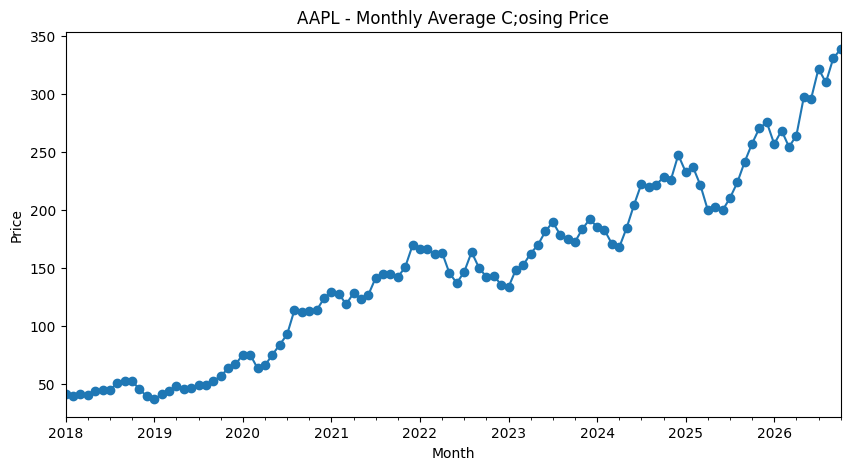

In [8]:
monthly.plot(
    marker = 'o', title = f"{TICKER} - Monthly Average C;osing Price"), plt.xlabel("Month"),plt.ylabel("Price")
plt.show()

In [9]:
series = monthly.copy()
series

Date
2018-01-01     40.639990
2018-02-01     39.264497
2018-03-01     40.920816
2018-04-01     39.827561
2018-05-01     43.617907
                 ...    
2026-06-01    296.164099
2026-07-01    322.010921
2026-08-01    310.130229
2026-09-01    331.056665
2026-10-01    338.847337
Freq: MS, Name: Close, Length: 106, dtype: float64

## AR Model:

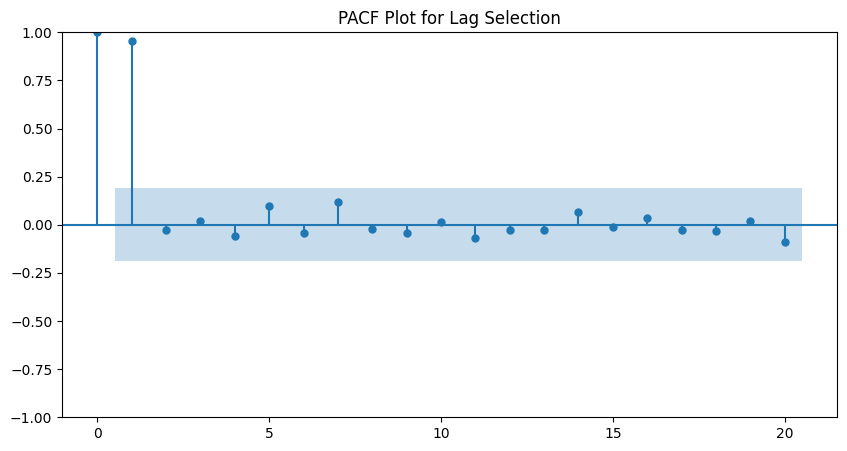

In [10]:
plot_pacf(series, lags = 20)
plt.title("PACF Plot for Lag Selection")
plt.show()

In [11]:
best_lag = 1
model = AutoReg(
    series, lags = best_lag
)
model_fit = model.fit()
model_fit

In [12]:
prediction = model_fit.predict(
    start = len(series), end = len(series) + 2
)
print("AR Model - Next 3 Predicted Values:")
print(prediction)

AR Model - Next 3 Predicted Values:
2026-11-01    343.744320
2026-12-01    348.694176
2027-01-01    353.697477
Freq: MS, dtype: float64


## MA Model — ARIMA(0,0,q)

In [13]:
model1 = ARIMA(series, order = (0,0,1))
model1_fit = model1.fit()
model2 = ARIMA(series, order = (0,0,2), enforce_invertibility = False)
model2_fit = model2.fit()
model3 = ARIMA(series, order = (0,0,3))
model3_fit = model3.fit()

C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


In [14]:
print("MA(1) AIC Score :", model1_fit.aic)
print("MA(2) AIC Score :", model2_fit.aic)
print("MA(3) AIC Score :", model3_fit.aic)

MA(1) AIC Score : 1105.4685668129125
MA(2) AIC Score : 1024.6352194036363
MA(3) AIC Score : 1014.9638166044839


In [15]:
q = 3
final_model = ARIMA(series, order = (0,0,q))
final_model_fit = final_model.fit()

C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


In [16]:
future = final_model_fit.forecast(steps = 3)
print("MA Model - Future Predictions")
print(future)

MA Model - Future Predictions
2026-11-01    298.569437
2026-12-01    256.835392
2027-01-01    210.450125
Freq: MS, Name: predicted_mean, dtype: float64


## ARMA Model - ARIMA(1,0,1)

In [17]:
model = ARIMA(series, order = (1,0,1))
model_fit = model.fit()

C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'


In [18]:
forecast = model_fit.forecast(steps = 3)
print("ARMA Model : Next 3 Predicted Values :")
print(forecast)

ARMA Model : Next 3 Predicted Values :
2026-11-01    338.928242
2026-12-01    338.380965
2027-01-01    337.835619
Freq: MS, Name: predicted_mean, dtype: float64


In [19]:
future_index = pd.date_range(series.index[-1] + pd.DateOffset(months = 1), periods = 3 , freq = "MS")

In [20]:
future_index

DatetimeIndex(['2026-11-01', '2026-12-01', '2027-01-01'], dtype='datetime64[s]', freq='MS')

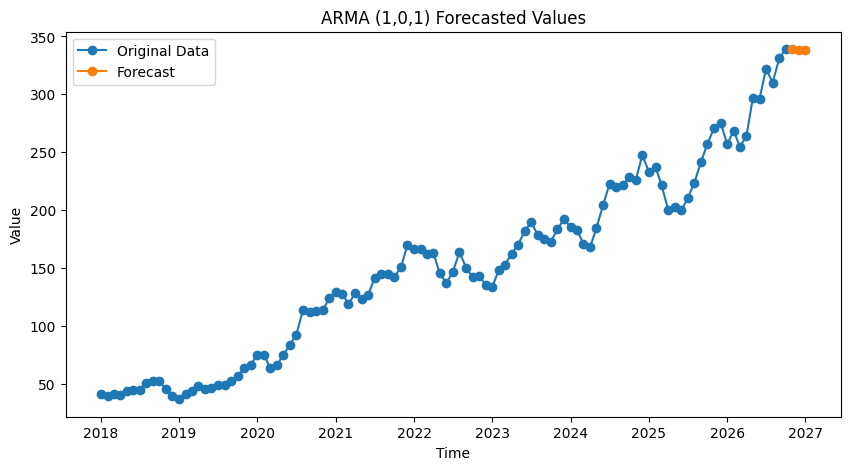

In [21]:
plt.plot(series.index, series, marker = 'o', label = "Original Data")
plt.plot(future_index, forecast, marker = 'o', label = "Forecast")
plt.xlabel("Time")
plt.ylabel("Value")
plt.title("ARMA (1,0,1) Forecasted Values")
plt.legend()
plt.show()

## ARIMA Model - Grid Search (p,d,q) by AIC

In [22]:
result = []
for p in range(4):
    for d in range(2):
        for q in range(4):
            try:
                model = ARIMA(series, order = (p,d,q))
                fitted_model = model.fit()
                result.append({
                    "p":p,
                    "d":d,
                    "q":q,
                    "Order": (p,d,q),
                    "AIC": fitted_model.aic
                })
            except Exception:
                continue
result_df = pd.DataFrame(result)
result_df = result_df.sort_values(by = "AIC")
print("Model Comparison")
print(result_df.head(10))

C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'


C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'


C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'


...

C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'


C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


Model Comparison
    p  d  q      Order         AIC
6   0  1  2  (0, 1, 2)  788.503311
20  2  1  0  (2, 1, 0)  789.900117
12  1  1  0  (1, 1, 0)  790.115001
4   0  1  0  (0, 1, 0)  790.118727
7   0  1  3  (0, 1, 3)  790.417008
14  1  1  2  (1, 1, 2)  790.467283
5   0  1  1  (0, 1, 1)  790.583523
22  2  1  2  (2, 1, 2)  790.669566
31  3  1  3  (3, 1, 3)  790.956171
13  1  1  1  (1, 1, 1)  791.254739


C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [23]:
best_row = result_df.iloc[0]
best_order = best_row["Order"]
best_aic = best_row["AIC"]
print("Best Order :",best_order, "| AIC :",best_aic)

Best Order : (0, 1, 2) | AIC : 788.5033106871816


In [24]:
final_model = ARIMA(series, order =  best_order)
final_result = final_model.fit()

In [25]:
final_result

In [26]:
forecast = final_result.forecast(steps = 5)
print("Forecast for the Next 5 Months :")
print(forecast)

Forecast for the Next 5 Months :
2026-11-01    344.034785
2026-12-01    345.874872
2027-01-01    345.874872
2027-02-01    345.874872
2027-03-01    345.874872
Freq: MS, Name: predicted_mean, dtype: float64


In [27]:
future_index = pd.date_range(series.index[-1] + pd.DateOffset(months = 1), periods = 5, freq = "MS")
future_index

DatetimeIndex(['2026-11-01', '2026-12-01', '2027-01-01', '2027-02-01',
               '2027-03-01'],
              dtype='datetime64[s]', freq='MS')

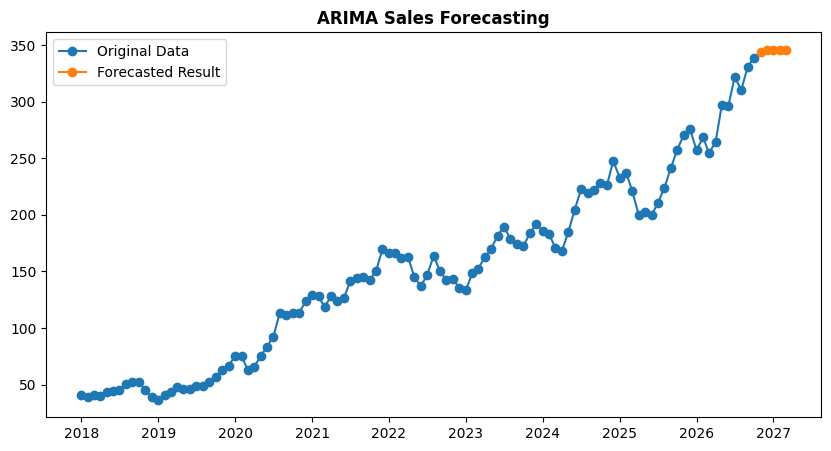

In [28]:
plt.plot(series.index, series, marker = 'o', label = "Original Data")
plt.plot(future_index, forecast,marker = 'o', label = "Forecasted Result")
plt.title("ARIMA Sales Forecasting", weight = 'bold')
plt.legend()
plt.show()

## SARIMA Model - SARIMAX(Order = (1,1,1))

In [29]:
df = monthly.to_frame(name = "Sales")
df.index.name = "Month"

In [30]:
model = SARIMAX(df['Sales'],order = (1,1,1),seasonal_order = (1,1,1,12))
model_fit = model.fit()

In [31]:
forecast = model_fit.forecast(steps = 12)
future_months = pd.date_range(
    start = df.index[-1] + pd.DateOffset(months = 1), periods = 12 , freq = 'MS'
)

In [32]:
forecast.index = future_months

In [33]:
forecast_df = pd.DataFrame({"Forecast Sales :" : forecast})
forecast_df

,Forecast Sales :
2026-11-01,346.335876
2026-12-01,355.451434
2027-01-01,343.094903
2027-02-01,349.806272
2027-03-01,338.028328
2027-04-01,337.494040
2027-05-01,354.076199
2027-06-01,356.494875
2027-07-01,374.147987
2027-08-01,372.599023


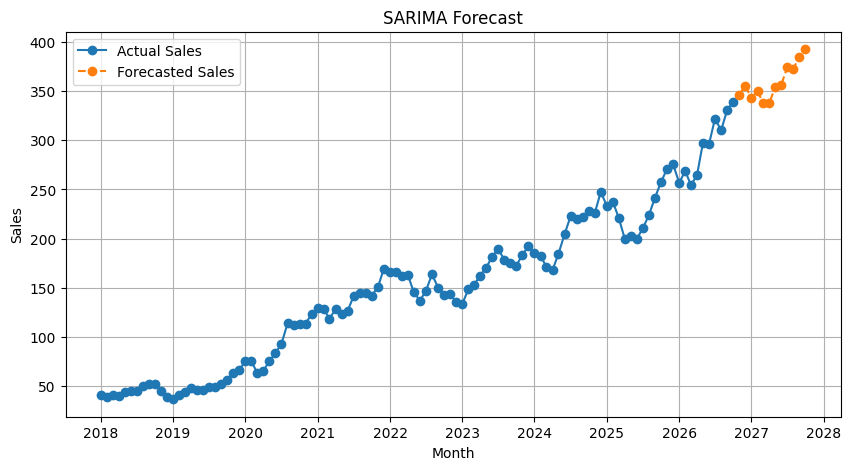

In [34]:
plt.plot(df.index, df['Sales'], marker = 'o',label = "Actual Sales")
plt.plot(forecast.index, forecast, marker = 'o', linestyle = '--', label = "Forecasted Sales")
plt.title("SARIMA Forecast")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid()
plt.show()

# ARIMAX Model - SARIMAX Order(1,1,1) with the Exog regressors.

In [35]:
exog_raw = raw.copy()

In [37]:
exog_raw['Range'] = exog_raw['High'] - exog_raw['Low']
exog_raw['Range']

Date
2018-01-02    0.710013
2018-01-03    0.604909
2018-01-04    0.324643
2018-01-05    0.541848
2018-01-08    0.392376
                ...   
2026-10-15    6.250000
2026-10-16    7.360016
2026-10-19    5.880005
2026-10-20    4.359985
2026-10-22    5.000000
Name: Range, Length: 2213, dtype: float64

In [38]:
exog_monthly = exog_raw[['Volume','Range']].resample('MS').mean().dropna()

In [39]:
common_index = df.index.intersection(exog_monthly.index)
y = df.loc[common_index, 'Sales']
X = exog_monthly.loc[common_index, ['Volume','Range']]
X.tail()

Price,Volume,Range
2026-06-01,6.672239e+07,8.367075
2026-07-01,5.449369e+07,7.696092
2026-08-01,4.297187e+07,6.211875
2026-09-01,4.282390e+07,7.182380
2026-10-01,3.601564e+07,5.670003


In [40]:
model = SARIMAX(y, exog = X, order = (1,1,1))
model_fit = model.fit()

C:\Users\Aaditya Raj Pandey\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [41]:
last_exog = X.iloc[-1]
future_exog = pd.DataFrame({
    "Volume" : [last_exog["Volume"]]*3,
    "Range": [last_exog['Range']]*3
})
future_exog

,Volume,Range
0,3.601564e+07,5.670003
1,3.601564e+07,5.670003
2,3.601564e+07,5.670003


In [42]:
forecast = model_fit.forecast(steps = 3, exog = future_exog)

In [43]:
future_dates = pd.date_range(
start = y.index[-1] + pd.DateOffset(months = 1), periods = 3, freq = 'MS'
)

In [44]:
forecast_df = pd.DataFrame({
    "Month" : future_dates,
    "Volume" : future_exog["Volume"],
    "Range" : future_exog["Range"],
    "Forecast Price" : forecast.values
})
forecast_df

,Month,Volume,Range,Forecast Price
0,2026-11-01,3.601564e+07,5.670003,340.610756
1,2026-12-01,3.601564e+07,5.670003,341.333049
2,2027-01-01,3.601564e+07,5.670003,341.628900


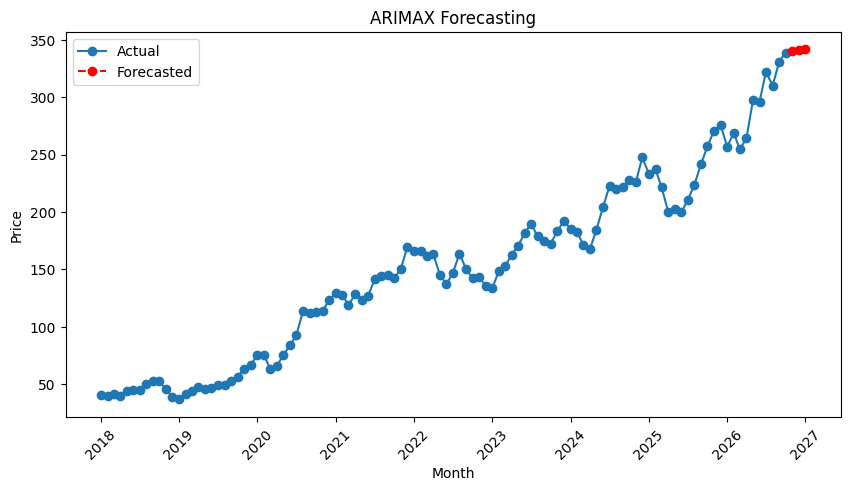

In [45]:
plt.plot(y.index, y, marker = 'o',label = 'Actual')
plt.plot(future_dates, forecast, marker = 'o',linestyle = '--',color = 'r', label = "Forecasted")
plt.title("ARIMAX Forecasting")
plt.xlabel("Month")
plt.ylabel("Price")
plt.legend()
plt.xticks(rotation = 45)
plt.show()